In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot
import matplotlib

In [2]:
def applyCut(inputDataframe, cut, text=None):
    dataframe = inputDataframe
    nbeforecut = dataframe.shape[0]
    cutDataframe = dataframe.query(cut)
    if text:
        print (text, cutDataframe.shape[0], ' fraction kept: %2.1f'%(100.0*float(cutDataframe.shape[0])/nbeforecut))
    return cutDataframe

In [3]:
def getData(observables, filename, treename):
    return (uproot.open(filename)[treename]).arrays(observables, library='pd')

In [4]:
def getRc(dataframe):
    n_ss = sum(dataframe[dataframe.b==1]['w'])
    n_os = sum(dataframe[dataframe.b==-1]['w'])
    return (n_ss-n_os)/(n_ss+n_os)

In [5]:
def getRcs(dataframe):
    n_ss = sum(dataframe[dataframe.bs==1]['ws'])
    n_os = sum(dataframe[dataframe.bs==-1]['ws'])
    return (n_ss-n_os)/(n_ss+n_os)

In [6]:
def getRcErr(dataframe):
    n_ss = sum(dataframe[dataframe.b==1]['w'])
    n_os = sum(dataframe[dataframe.b==-1]['w'])
    n_unweighted = dataframe[dataframe.b==1].shape[0] + dataframe[dataframe.b==-1].shape[0]
    #p = n_ss/(n_ss+n_os)
    return 2*np.sqrt( n_ss * n_os / ((n_ss+n_os)**2 * n_unweighted) )

In [7]:
def getRcsErr(dataframe):
    n_ss = sum(dataframe[dataframe.bs==1]['ws'])
    n_os = sum(dataframe[dataframe.bs==-1]['ws'])
    n_unweighted = dataframe[dataframe.bs==1].shape[0] + dataframe[dataframe.bs==-1].shape[0]
    #p = n_ss/(n_ss+n_os)
    return 2*np.sqrt( n_ss * n_os / ((n_ss+n_os)**2 * n_unweighted) )

In [22]:
# suppose this is wrong
def getRcAndErr(df, ob):
    if (ob == 'b'):
        nos = sum(df[df.b==-1]['w'])
        nss = sum(df[df.b==+1]['w'])
    elif (ob == 'b_ch'):
        nos = sum(df[df.b_ch==-1]['w'])
        nss = sum(df[df.b_ch==+1]['w'])
    elif (ob == 'bs'):
        nos = sum(df[df.bs==-1]['w'])
        nss = sum(df[df.bs==+1]['w'])
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    n_array = []
    wtot_array = []
    for i in range(0, len(w_array)):
        n_array.append( df[df.w == w_array[i]].shape[0] )
        wtot_array.append( sum(df[df.w == w_array[i]]['w']) )
    n = 0
    for i in range(0, len(w_array)):
        if (wtot_array[i] != 0):
            n += wtot_array[i]*n_array[i]/sum(wtot_array)
    rc_err = 2*np.sqrt(p*(1-p)/n)
    return rc, rc_err

In [8]:
def getRcAndErr(df, ob):
    if (ob == 'b'):
        nos = sum(df[df.b==-1]['w'])
        nss = sum(df[df.b==+1]['w'])
        n_unweighted = df[df.b==1].shape[0] + df[df.b==-1].shape[0]
    elif (ob == 'bs'):
        nos = sum(df[df.bs==-1]['w'])
        nss = sum(df[df.bs==+1]['w'])
        n_unweighted = df[df.bs==1].shape[0] + df[df.bs==-1].shape[0]
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    rc_err = 2*np.sqrt(p*(1-p)/n_unweighted)
    return rc, rc_err

In [9]:
def calc_hist(vals, bins=10, weights=None, density=False):
    
    if weights is None:
        weights = np.ones(vals.shape)
    
    # compute histogram
    hist, bins = np.histogram(vals, bins=bins, weights=weights)
    
    # compute which bins the values are in
    digits = np.digitize(vals, bins)

    # compute the errors per bin
    # note that lowest bin value that digitize returns is 1
    # hence the range in the following list comprehension should start at 1
    errs = np.asarray([np.linalg.norm(weights[digits==i]) for i in range(1, len(bins))])

    # handle normalization
    if density:
        density_int = weights.sum() * (bins[1] - bins[0])
        hist /= density_int
        errs /= density_int
        
    return hist, errs, bins

In [10]:
def w_norm_per_xbin(h,x,y):
    w = np.empty([len(x)-1,len(y)-1])
    for i in range(0,len(x)-1):
        for j in range(0,len(y)-1):
            w[i][j] = h[i][j]/sum(h[i]) + 10**-50
    return w

In [11]:
observables1 = ['pt','b','dr','z','epair','w','reject','pt1','pt2','qlead','qsublead','y1','y2','phi1','phi2']
observabless1 = ['pts','bs','drs','zs','epairs','ws','rejects','pt1s','pt2s','qleads','qsubleads','y1s','y2s','phi1s','phi2s']

In [12]:
df_allreco = applyCut(getData(observables1+observabless1, '/vast/palmer/home.grace/ys668/output/run12/all0615_chargedrc.root', "MatchedTree"),\
                      'pts>15 and bs!=-9 and reject<=0 and rejects<=0')

In [13]:
df_allreco = applyCut(df_allreco, 'not (pts>25 and w>4e-9)') # removes one high weight jet

In [17]:
df_fake1 = applyCut(df_allreco, 'pt==-9')

In [18]:
df_fake2 = applyCut(df_allreco, 'pt!=-9 and b==-9')

In [19]:
df_fake3 = applyCut(df_allreco, 'pt!=-9 and b!=-9 and (distance1>0.02 or distance2>0.02)')

In [20]:
df_allfake = applyCut(df_allreco, 'pt==-9 or b==-9 or distance1>0.02 or distance2>0.02')

In [21]:
df_notfakejet = applyCut(df_allreco, 'pt!=-9')

In [14]:
df = applyCut(getData(observables1+observabless1, '/vast/palmer/home.grace/ys668/output/run12/all0615_chargedrc.root', "MatchedTree"),\
              'pts>15 and bs!=-9 and b!=-9 and reject<=0 and rejects<=0')

In [15]:
distance1 = []
distance2 = []
for i in range(0,df.shape[0]):
    phi1small = min(df.iloc[i]['phi1'], df.iloc[i]['phi1s'])
    phi1large = max(df.iloc[i]['phi1'], df.iloc[i]['phi1s'])
    phi2small = min(df.iloc[i]['phi2'], df.iloc[i]['phi2s'])
    phi2large = max(df.iloc[i]['phi2'], df.iloc[i]['phi2s'])
    dphi1 = min(phi1large-phi1small, 6.283185307179586-(phi1large-phi1small))
    dphi2 = min(phi2large-phi2small, 6.283185307179586-(phi2large-phi2small))
    if (dphi1 > np.pi):
        print(df.iloc[i]['phi1'], df.iloc[i]['phi1s'], dphi1)
    distance1.append(np.sqrt(dphi1**2+(df.iloc[i]['y1']-df.iloc[i]['y1s'])**2))
    distance2.append(np.sqrt(dphi2**2+(df.iloc[i]['y2']-df.iloc[i]['y2s'])**2))
df['distance1'] = distance1
df['distance2'] = distance2

In [16]:
distance1 = []
distance2 = []
for i in range(0,df_allreco.shape[0]):
    phi1small = min(df_allreco.iloc[i]['phi1'], df_allreco.iloc[i]['phi1s'])
    phi1large = max(df_allreco.iloc[i]['phi1'], df_allreco.iloc[i]['phi1s'])
    phi2small = min(df_allreco.iloc[i]['phi2'], df_allreco.iloc[i]['phi2s'])
    phi2large = max(df_allreco.iloc[i]['phi2'], df_allreco.iloc[i]['phi2s'])
    dphi1 = min(phi1large-phi1small, 6.283185307179586-(phi1large-phi1small))
    dphi2 = min(phi2large-phi2small, 6.283185307179586-(phi2large-phi2small))
    if (dphi1 > np.pi):
        print(df_allreco.iloc[i]['phi1'], df_allreco.iloc[i]['phi1s'], dphi1)
    distance1.append(np.sqrt(dphi1**2+(df_allreco.iloc[i]['y1']-df_allreco.iloc[i]['y1s'])**2))
    distance2.append(np.sqrt(dphi2**2+(df_allreco.iloc[i]['y2']-df_allreco.iloc[i]['y2s'])**2))
df_allreco['distance1'] = distance1
df_allreco['distance2'] = distance2

Matches

In [20]:
df_match = applyCut(df, 'distance1 < 0.02 and distance2 < 0.02')

In [21]:
df_match.shape[0]

46086

Text(0.5, 0, 'allfakeed jet pts [GeV]')

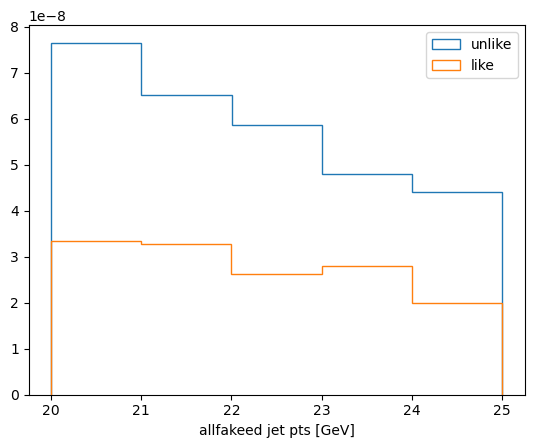

In [349]:
plt.hist(df_allfake[(df_allfake.pts>20) & (df_allfake.pts<25) & (df_allfake.b==-1)]['pts'], bins=5, \
         weights=df_allfake[(df_allfake.pts>20) & (df_allfake.pts<25) & (df_allfake.b==-1)]['w'], histtype='step', label='unlike')
plt.hist(df_allfake[(df_allfake.pts>20) & (df_allfake.pts<25) & (df_allfake.b==1)]['pts'], bins=5,\
         weights=df_allfake[(df_allfake.pts>20) & (df_allfake.pts<25) & (df_allfake.b==1)]['w'], histtype='step', label='like')
plt.legend()
plt.xlabel('allfake jet pts [GeV]')

Text(0.5, 0, 'Matched jet truth pT [GeV]')

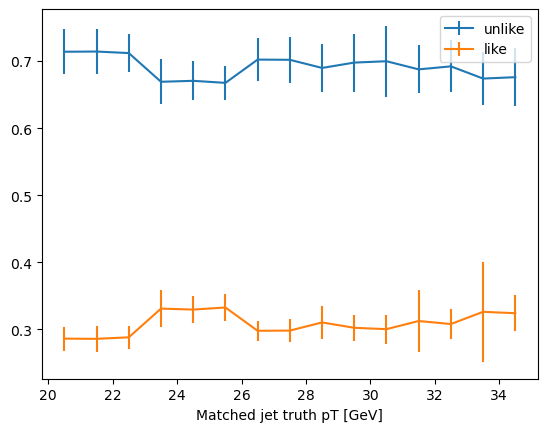

In [55]:
y_os, yerr_os, x = calc_hist(df_match[df_match.b==-1]['pt'], bins=np.arange(20,36), \
         weights=df_match[df_match.b==-1]['w'])#, histtype='step')
y_ss, yerr_ss, x = calc_hist(df_match[df_match.b==1]['pt'], bins=np.arange(20,36), \
         weights=df_match[df_match.b==1]['w'])#, histtype='step', label='like')
x = np.arange(20.5,35.5)
plt.errorbar(x, y_os/(y_os+y_ss), yerr=yerr_os/(y_os+y_ss), label='unlike')
plt.errorbar(x, y_ss/(y_os+y_ss), yerr=yerr_ss/(y_os+y_ss), label='like')
plt.legend()
plt.xlabel('Matched jet truth pT [GeV]')
#plt.yscale('log')

Text(0.5, 0, 'Matched jet truth pT [GeV]')

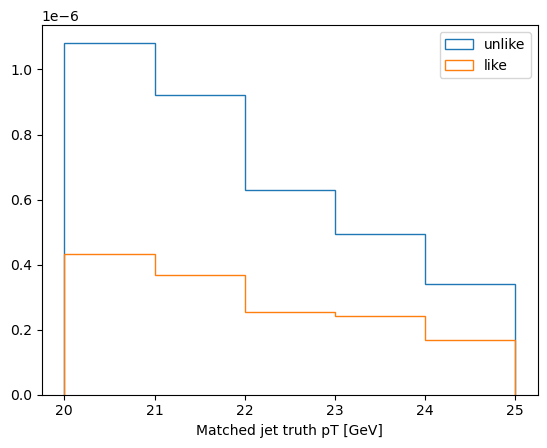

In [56]:
plt.hist(df_match[(df_match.pt>20) & (df_match.pt<25) & (df_match.b==-1)]['pt'], bins=5, \
         weights=df_match[(df_match.pt>20) & (df_match.pt<25) & (df_match.b==-1)]['w'], histtype='step', label='unlike')
plt.hist(df_match[(df_match.pt>20) & (df_match.pt<25) & (df_match.b==1)]['pt'], bins=5,\
         weights=df_match[(df_match.pt>20) & (df_match.pt<25) & (df_match.b==1)]['w'], histtype='step', label='like')
plt.legend()
plt.xlabel('Matched jet truth pT [GeV]')

In [112]:
np.unique(df_match['w'])

array([2.15385002e-11, 1.27623315e-10, 5.68292191e-10, 3.41630102e-09,
       1.43789896e-08, 1.94674001e-08, 8.28750188e-08])

In [124]:
h,x,y = np.histogram2d(df_match['pts'],df_match['w'], \
                       bins=[np.arange(16,42,2),[2e-11,1e-10,5e-10,1e-9,1e-8,1.5e-8,8e-8,1e-7]],weights=df_match['w'])#, density=True)

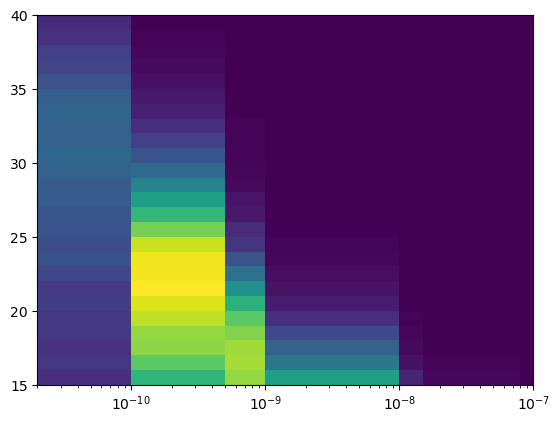

In [117]:
plt.hist2d(df_match['w'],df_match['pts'], bins=[[2e-11,1e-10,5e-10,1e-9,1e-8,1.5e-8,8e-8,1e-7],)
plt.xscale('log')

(15.0, 40.0)

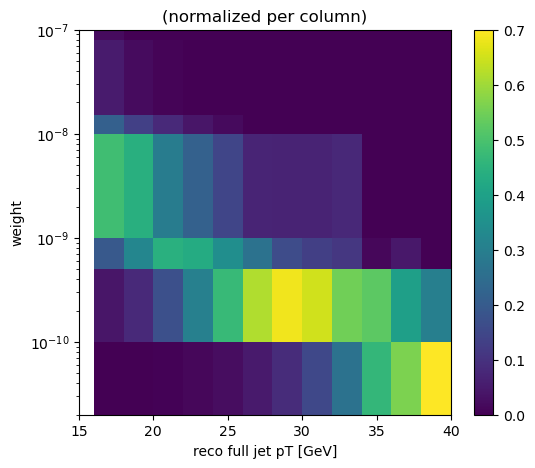

In [126]:
plt.figure(figsize=(6,5))
w = w_norm_per_xbin(h,np.arange(16,42,2),[2e-11,1e-10,5e-10,1e-9,1e-8,1.5e-8,8e-8,1e-7])
plt.pcolormesh(np.arange(16,42,2),[2e-11,1e-10,5e-10,1e-9,1e-8,1.5e-8,8e-8,1e-7], np.transpose(w))
plt.xlabel('reco full jet pT [GeV]')
plt.ylabel('weight')
plt.yscale('log')
plt.title('(normalized per column)')
plt.colorbar()
plt.xlim(15,40)
#plt.ylim(5,40)
#plt.clim(0,1)

Response matrices

In [17]:
h,x,y = np.histogram2d(df_match['pt'],df_match['pts'], bins=([5,10,15,20,25,30,40]), weights=df_match['w'], density=True)

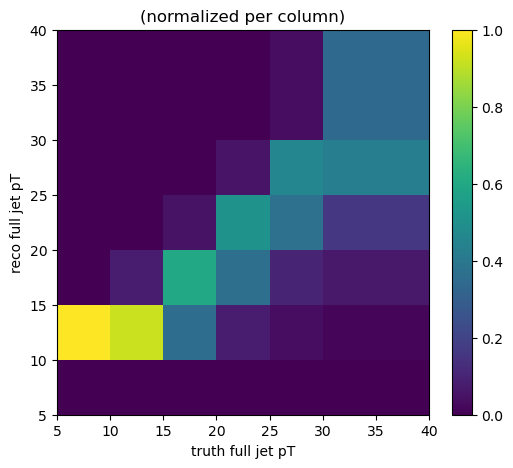

In [18]:
plt.figure(figsize=(6,5))
w = w_norm_per_xbin(h,[5,10,15,20,25,30,40],[5,10,15,20,25,30,40])
plt.pcolormesh([5,10,15,20,25,30,40],[5,10,15,20,25,30,40], np.transpose(w))
plt.xlabel('truth full jet pT [GeV]')
plt.ylabel('reco full jet pT [GeV]')
plt.title('(normalized per column)')
plt.colorbar()
plt.xlim(5,40)
plt.ylim(5,40)
plt.clim(0,1)

In [19]:
h,x,y = np.histogram2d(df_match['pts'],df_match['pt'], bins=([5,10,15,20,25,30,40]), weights=df_match['w'], density=True)

/tmp/ipykernel_27292/2021765472.py:5: RuntimeWarning: invalid value encountered in scalar divide
  w[i][j] = h[i][j]/sum(h[i]) + 10**-50


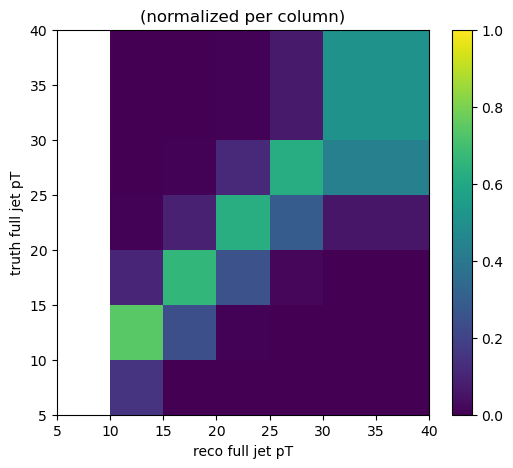

In [20]:
plt.figure(figsize=(6,5))
w = w_norm_per_xbin(h,[5,10,15,20,25,30,40],[5,10,15,20,25,30,40])
plt.pcolormesh([5,10,15,20,25,30,40],[5,10,15,20,25,30,40], np.transpose(w))
plt.xlabel('reco full jet pT [GeV]')
plt.ylabel('truth full jet pT [GeV]')
plt.title('(normalized per column)')
plt.colorbar()
plt.xlim(5,40)
plt.ylim(5,40)
plt.clim(0,1)

In [120]:
rc_00 = getRc(applyCut(df_match,'15<pt<20'))
rc_err_00 = getRcErr(applyCut(df_match,'15<pt<20'))

In [121]:
rc_0 = getRc(applyCut(df_match,'20<pt<25'))
rc_err_0 = getRcErr(applyCut(df_match,'20<pt<25'))

In [122]:
rc_1 = getRc(applyCut(df_match,'25<pt<30'))
rc_err_1 = getRcErr(applyCut(df_match,'25<pt<30'))

In [123]:
rc_2 = getRc(applyCut(df_match,'30<pt<40'))
rc_err_2 = getRcErr(applyCut(df_match,'30<pt<40'))

In [124]:
rcs_00 = getRcs(applyCut(df_match,'15<pt<20'))
rcs_err_00 = getRcsErr(applyCut(df_match,'15<pt<20'))

In [125]:
rcs_0 = getRcs(applyCut(df_match,'20<pt<25'))
rcs_err_0 = getRcsErr(applyCut(df_match,'20<pt<25'))

In [126]:
rcs_1 = getRcs(applyCut(df_match,'25<pt<30'))
rcs_err_1 = getRcsErr(applyCut(df_match,'25<pt<30'))

In [127]:
rcs_2 = getRcs(applyCut(df_match,'30<pt<40'))
rcs_err_2 = getRcsErr(applyCut(df_match,'30<pt<40'))

Text(0.5, 1.0, 'Matching cut: truth pT > 15 GeV, truth Nch > 2, reco Nch > 2, dR(truth,reco) < 0.02')

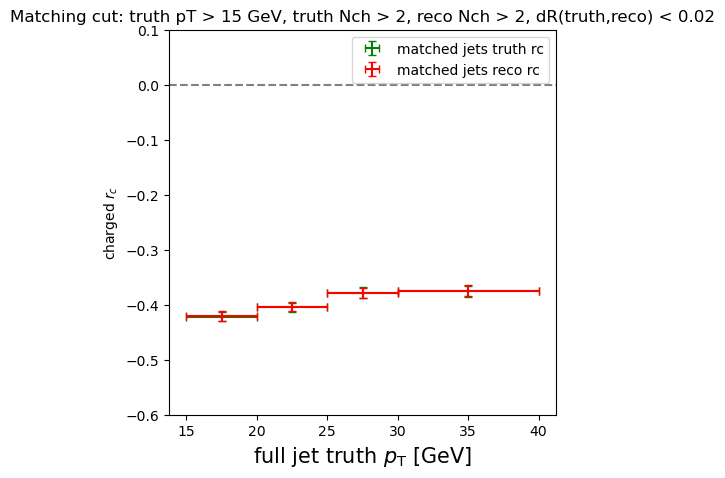

In [128]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([17.5, 22.5, 27.5, 35], [rc_00, rc_0, rc_1, rc_2], xerr=[2.5, 2.5, 2.5, 5], yerr=[rc_err_00, rc_err_0, rc_err_1, rc_err_2], capsize=3, color='g', ls='none', label='matched jets truth rc')
plt.errorbar([17.5, 22.5, 27.5, 35], [rcs_00, rcs_0, rcs_1, rcs_2], xerr=[2.5, 2.5, 2.5, 5], yerr=[rcs_err_00, rcs_err_0, rcs_err_1, rcs_err_2], capsize=3, color='r', ls='none', label='matched jets reco rc')
plt.xlabel('full jet truth $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('charged $r_c$')
plt.ylim(-0.6,0.1)
plt.legend()
plt.title('Matching cut: truth pT > 15 GeV, truth Nch > 2, reco Nch > 2, dR(truth,reco) < 0.02')

In [26]:
w_array = np.unique(df_allreco['w'])

In [35]:
df_allreco_pts_array = [ df_allreco[(df_allreco.pts>15) & (df_allreco.pts<20)],\
                       df_allreco[(df_allreco.pts>20) & (df_allreco.pts<25)],\
                       df_allreco[(df_allreco.pts>25) & (df_allreco.pts<30)],\
                       df_allreco[(df_allreco.pts>30) & (df_allreco.pts<40)] ]

In [36]:
rc_allreco_bs_vs_pts_array = []
rc_err_allreco_bs_vs_pts_array = []
for i in range(0, len(df_allreco_pts_array)):
    rc_allreco_bs_vs_pts_array.append(getRcAndErr(df_allreco_pts_array[i], 'bs')[0])
    rc_err_allreco_bs_vs_pts_array.append(getRcAndErr(df_allreco_pts_array[i], 'bs')[1])

In [23]:
df_match_pts_array = [ df_match[(df_match.pts>15) & (df_match.pts<20)],\
                       df_match[(df_match.pts>20) & (df_match.pts<25)],\
                       df_match[(df_match.pts>25) & (df_match.pts<30)],\
                       df_match[(df_match.pts>30) & (df_match.pts<40)] ]

In [27]:
rc_match_bs_vs_pts_array = []
rc_err_match_bs_vs_pts_array = []
for i in range(0, len(df_match_pts_array)):
    rc_match_bs_vs_pts_array.append(getRcAndErr(df_match_pts_array[i], 'bs')[0])
    rc_err_match_bs_vs_pts_array.append(getRcAndErr(df_match_pts_array[i], 'bs')[1])

In [29]:
df_allfake_pts_array = [ df_allfake[(df_allfake.pts>15) & (df_allfake.pts<20)],\
                       df_allfake[(df_allfake.pts>20) & (df_allfake.pts<25)],\
                       df_allfake[(df_allfake.pts>25) & (df_allfake.pts<30)],\
                       df_allfake[(df_allfake.pts>30) & (df_allfake.pts<40)] ]

In [30]:
rc_allfake_bs_vs_pts_array = []
rc_err_allfake_bs_vs_pts_array = []
for i in range(0, len(df_allfake_pts_array)):
    rc_allfake_bs_vs_pts_array.append(getRcAndErr(df_allfake_pts_array[i], 'bs')[0])
    rc_err_allfake_bs_vs_pts_array.append(getRcAndErr(df_allfake_pts_array[i], 'bs')[1])

In [55]:
df_fake1_pts_array = [ df_fake1[(df_fake1.pts>15) & (df_fake1.pts<20)],\
                       df_fake1[(df_fake1.pts>20) & (df_fake1.pts<25)],\
                       df_fake1[(df_fake1.pts>25) & (df_fake1.pts<30)],\
                       df_fake1[(df_fake1.pts>30) & (df_fake1.pts<40)] ]

In [56]:
rc_fake1_bs_vs_pts_array = []
rc_err_fake1_bs_vs_pts_array = []
for i in range(0, len(df_fake1_pts_array)):
    rc_fake1_bs_vs_pts_array.append(getRcAndErr(df_fake1_pts_array[i], 'bs')[0])
    rc_err_fake1_bs_vs_pts_array.append(getRcAndErr(df_fake1_pts_array[i], 'bs')[1])

In [65]:
df_fake2_pts_array = [ df_fake2[(df_fake2.pts>15) & (df_fake2.pts<20)],\
                       df_fake2[(df_fake2.pts>20) & (df_fake2.pts<25)],\
                       df_fake2[(df_fake2.pts>25) & (df_fake2.pts<30)],\
                       df_fake2[(df_fake2.pts>30) & (df_fake2.pts<40)] ]

In [66]:
rc_fake2_bs_vs_pts_array = []
rc_err_fake2_bs_vs_pts_array = []
for i in range(0, len(df_fake2_pts_array)):
    rc_fake2_bs_vs_pts_array.append(getRcAndErr(df_fake2_pts_array[i], 'bs')[0])
    rc_err_fake2_bs_vs_pts_array.append(getRcAndErr(df_fake2_pts_array[i], 'bs')[1])

In [67]:
df_fake3_pts_array = [ df_fake3[(df_fake3.pts>15) & (df_fake3.pts<20)],\
                       df_fake3[(df_fake3.pts>20) & (df_fake3.pts<25)],\
                       df_fake3[(df_fake3.pts>25) & (df_fake3.pts<30)],\
                       df_fake3[(df_fake3.pts>30) & (df_fake3.pts<40)] ]

In [70]:
rc_fake3_bs_vs_pts_array = []
rc_err_fake3_bs_vs_pts_array = []
for i in range(0, len(df_fake3_pts_array)):
    rc_fake3_bs_vs_pts_array.append(getRcAndErr(df_fake3_pts_array[i], 'bs')[0])
    rc_err_fake3_bs_vs_pts_array.append(getRcAndErr(df_fake3_pts_array[i], 'bs')[1])

Text(0.5, 1.0, '')

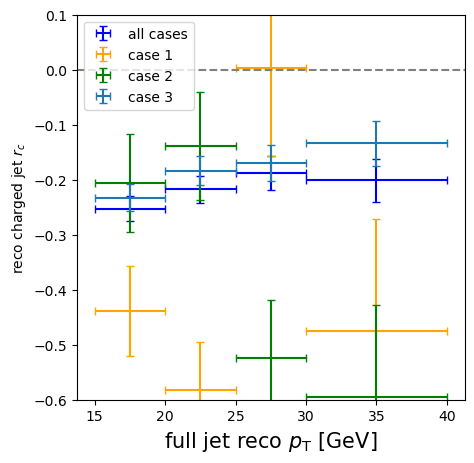

In [75]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([17.5, 22.5, 27.5, 35], rc_allfake_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5], yerr=rc_err_allfake_bs_vs_pts_array, capsize=3, color='b', ls='none', label='all cases')
plt.errorbar([17.5, 22.5, 27.5, 35], rc_fake1_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5], yerr=rc_err_fake1_bs_vs_pts_array, capsize=3, color='orange', ls='none', label='case 1')
plt.errorbar([17.5, 22.5, 27.5, 35], rc_fake2_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5], yerr=rc_err_fake2_bs_vs_pts_array, capsize=3, color='g', ls='none', label='case 2')
plt.errorbar([17.5, 22.5, 27.5, 35], rc_fake3_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5], yerr=rc_err_fake3_bs_vs_pts_array, capsize=3, ls='none', label='case 3')
plt.xlabel('full jet reco $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('reco charged jet $r_c$')
plt.ylim(-0.6,0.1)
plt.legend(loc='upper left')
plt.title('')

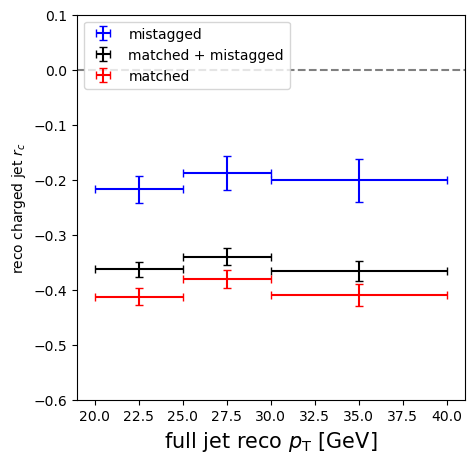

In [78]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([22.5, 27.5, 35], rc_allfake_bs_vs_pts_array[1:], xerr=[2.5, 2.5, 5], yerr=rc_err_allfake_bs_vs_pts_array[1:], capsize=3, color='b', ls='none', label='mistagged')
plt.errorbar([22.5, 27.5, 35], rc_allreco_bs_vs_pts_array[1:], xerr=[2.5, 2.5, 5], yerr=rc_err_allreco_bs_vs_pts_array[1:], capsize=3, color='k', ls='none', label='matched + mistagged')
plt.errorbar([22.5, 27.5, 35], rc_match_bs_vs_pts_array[1:], xerr=[2.5, 2.5, 5], yerr=rc_err_match_bs_vs_pts_array[1:], capsize=3, color='r', ls='none', label='matched')
plt.xlabel('full jet reco $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('reco charged jet $r_c$')
plt.ylim(-0.6,0.1)
plt.legend(loc='upper left')
#plt.title('Matching cut: truth pT > 5 GeV, truth Nch > 2, reco Nch > 2, dR(truth,reco) < 0.02')

Text(0.5, 1.0, 'Matching cut: truth pT > 5 GeV, truth Nch > 2, reco Nch > 2, dR(truth,reco) < 0.02')

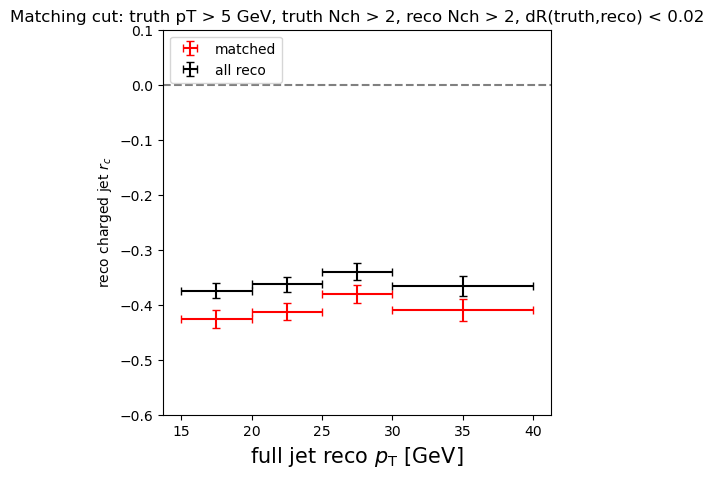

In [41]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([17.5, 22.5, 27.5, 35], rc_match_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5], yerr=rc_err_match_bs_vs_pts_array, capsize=3, color='r', ls='none', label='matched')
plt.errorbar([17.5, 22.5, 27.5, 35], rc_allreco_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5], yerr=rc_err_allreco_bs_vs_pts_array, capsize=3, color='k', ls='none', label='all reco')
plt.xlabel('full jet reco $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('reco charged jet $r_c$')
plt.ylim(-0.6,0.1)
plt.legend(loc='upper left')
plt.title('Matching cut: truth pT > 5 GeV, truth Nch > 2, reco Nch > 2, dR(truth,reco) < 0.02')

In [47]:
np.array(rc_allreco_bs_vs_pts_array)-np.array(rc_match_bs_vs_pts_array)

array([0.05049298, 0.04976062, 0.04134469, 0.04356509])

Text(0.5, 1.0, 'Matching cut: truth pT > 5 GeV, truth Nch > 2, reco Nch > 2, dR(truth,reco) < 0.02')

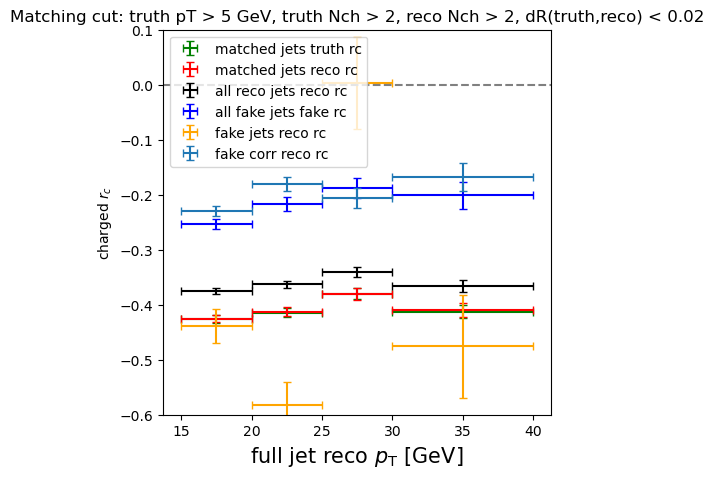

In [381]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([17.5, 22.5, 27.5, 35], [rc_00, rc_0, rc_1, rc_2], xerr=[2.5, 2.5, 2.5, 5], yerr=[rc_err_00, rc_err_0, rc_err_1, rc_err_2], capsize=3, color='g', ls='none', label='matched jets truth rc')
plt.errorbar([17.5, 22.5, 27.5, 35], [rcs_00, rcs_0, rcs_1, rcs_2], xerr=[2.5, 2.5, 2.5, 5], yerr=[rcs_err_00, rcs_err_0, rcs_err_1, rcs_err_2], capsize=3, color='r', ls='none', label='matched jets reco rc')
plt.errorbar([17.5, 22.5, 27.5, 35], [rcs_00_allreco, rcs_0_allreco, rcs_1_allreco, rcs_2_allreco], xerr=[2.5, 2.5, 2.5, 5], yerr=[rcs_err_00_allreco, rcs_err_0_allreco, rcs_err_1_allreco, rcs_err_2_allreco], capsize=3, color='k', ls='none', label='all reco jets reco rc')
plt.errorbar([17.5, 22.5, 27.5, 35], [rcs_00_allfake, rcs_0_allfake, rcs_1_allfake, rcs_2_allfake], xerr=[2.5, 2.5, 2.5, 5], yerr=[rcs_err_00_allfake, rcs_err_0_allfake, rcs_err_1_allfake, rcs_err_2_allfake], capsize=3, color='b', ls='none', label='all fake jets fake rc')
plt.errorbar([17.5, 22.5, 27.5, 35], [rcs_00_fakejet, rcs_0_fakejet, rcs_1_fakejet, rcs_2_fakejet], xerr=[2.5, 2.5, 2.5, 5], yerr=[rcs_err_00_fakejet, rcs_err_0_fakejet, rcs_err_1_fakejet, rcs_err_2_fakejet], capsize=3, color='orange', ls='none', label='fake jets reco rc')
plt.errorbar([17.5, 22.5, 27.5, 35], [rcs_00_fakecorr, rcs_0_fakecorr, rcs_1_fakecorr, rcs_2_fakecorr], xerr=[2.5, 2.5, 2.5, 5], yerr=[rcs_err_00_fakecorr, rcs_err_0_fakecorr, rcs_err_1_fakecorr, rcs_err_2_fakecorr], capsize=3, ls='none', label='fake corr reco rc')
plt.xlabel('full jet reco $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('charged $r_c$')
plt.ylim(-0.6,0.1)
plt.legend(loc='upper left')
plt.title('Matching cut: truth pT > 5 GeV, truth Nch > 2, reco Nch > 2, dR(truth,reco) < 0.02')

Investigate high weight jets

In [384]:
print(df_fakejet_20[(df_fakejet_20.bs==-1) & (df_fakejet_20.w>4e-9)].shape[0])
print(df_fakejet_20[(df_fakejet_20.bs==1) & (df_fakejet_20.w>4e-9)].shape[0])

2
0


In [385]:
print(df_fakejet_25[(df_fakejet_25.bs==-1) & (df_fakejet_25.w>5e-10)].shape[0])
print(df_fakejet_25[(df_fakejet_25.bs==1) & (df_fakejet_25.w>5e-10)].shape[0])

9
2


In [386]:
print(df_fakejet_30[(df_fakejet_30.bs==-1) & (df_fakejet_30.w>5e-10)].shape[0])
print(df_fakejet_30[(df_fakejet_30.bs==1) & (df_fakejet_30.w>5e-10)].shape[0])

2
1


In [387]:
print(df_notfakejet_20[df_notfakejet_20.w>4e-9].shape[0])
print(df_notfakejet_25[df_notfakejet_25.w>5e-10].shape[0])
print(df_notfakejet_30[df_notfakejet_30.w>5e-10].shape[0])

26
609
75


In [388]:
print(df_fakejet_20.shape[0])
print(df_notfakejet_20.shape[0])

379
19584


In [389]:
np.unique(df_allreco['w'])

array([2.15385002e-11, 1.27623315e-10, 5.68292191e-10, 3.41630102e-09,
       1.43789896e-08, 1.94674001e-08, 8.28750188e-08])

In [202]:
print(max(df_fakejet_25['w']))
print(max(df_notfakejet_25['w']))

3.416301019854018e-09
3.416301019854018e-09


Fake subtraction

In [48]:
ob = 'b'
range_low = -1.2
range_high = 1.2
bins = 2

In [49]:
df_match_20 = applyCut(df_match, '20 < pts < 25')
df_allreco_20 = applyCut(df_allreco, '20 < pts < 25')
df_fake_20 = applyCut(df_allfake, '20 < pts < 25')
df_fakejet_20 = applyCut(df_fakejet, '20 < pts < 25')
df_fakecorr_20 = applyCut(df_fakecorr, '20 < pts < 25')
df_notfakejet_20 = applyCut(df_notfakejet, '20 < pts < 25')

In [50]:
y_match_rec,yerr_match_rec,x = calc_hist(df_match_20[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_match_20['w'], density=True)
y_allreco_rec,yerr_allreco_rec,x = calc_hist(df_allreco_20[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_allreco_20['w'], density=True)
y_fake_rec,yerr_fake_rec,x = calc_hist(df_fake_20[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_fake_20['w'], density=True)
y_fakejet_rec,yerr_fakejet_rec,x = calc_hist(df_fakejet_20[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_fakejet_20['w'], density=True)
y_notfakejet_rec,yerr_notfakejet_rec,x = calc_hist(df_notfakejet_20[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_notfakejet_20['w'], density=True)
y_fakecorr_rec,yerr_fakecorr_rec,x = calc_hist(df_fakecorr_20[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_fakecorr_20['w'], density=True)

(0.0, 0.9950139788690435)

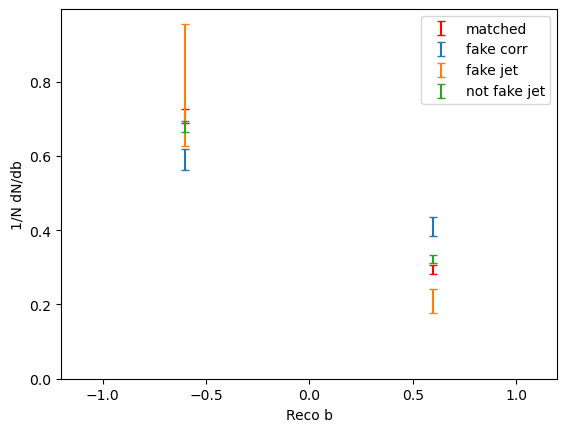

In [46]:
x=np.arange(range_low+(range_high-range_low)/(2*bins),range_high+(range_high-range_low)/(2*bins), (range_high-range_low)/bins)
#plt.errorbar(x, y_allreco_rec/sum(y_allreco_rec), yerr=yerr_allreco_rec/sum(y_allreco_rec), capsize=3, color='k', label='all reco', ls='none')
plt.errorbar(x, y_match_rec/sum(y_match_rec), yerr=yerr_match_rec/sum(y_match_rec), capsize=3, color='r', label='matched', ls='none')
#plt.errorbar(x, y_fake_rec/sum(y_fake_rec), yerr=yerr_fake_rec/sum(y_fake_rec), capsize=3, color='b', label='all fake', ls='none')
plt.errorbar(x, y_fakecorr_rec/sum(y_fakecorr_rec), yerr=yerr_fakecorr_rec/sum(y_fakecorr_rec), capsize=3, label='fake corr', ls='none')
plt.errorbar(x, y_fakejet_rec/sum(y_fakejet_rec), yerr=yerr_fakejet_rec/sum(y_fakejet_rec), capsize=3, label='fake jet', ls='none')
plt.errorbar(x, y_notfakejet_rec/sum(y_notfakejet_rec), yerr=yerr_notfakejet_rec/sum(y_notfakejet_rec), capsize=3, label='not fake jet', ls='none')
plt.legend()
plt.xlabel('Reco '+ob)
plt.ylabel('1/N dN/d'+ob)
plt.xlim(range_low,range_high)
plt.ylim(bottom=0)

In [45]:
print(y_fake_rec/sum(y_fake_rec))
print(yerr_fake_rec/sum(y_fake_rec))

[0.60864417 0.39135583]
[0.02912147 0.02331168]


In [51]:
print(y_match_rec/sum(y_match_rec))
print(yerr_match_rec/sum(y_match_rec))

[0.70636007 0.29363993]
[0.0189809  0.01136867]


In [47]:
print(y_fakejet_rec/sum(y_fakejet_rec))
print(yerr_fakejet_rec/sum(y_fakejet_rec))

[0.79143631 0.20856369]
[0.16456544 0.03280639]


In [48]:
print(y_fake_rec/sum(y_fake_rec))
print(yerr_fake_rec/sum(y_fake_rec))

[0.60864417 0.39135583]
[0.02912147 0.02331168]


In [49]:
(y_allreco_rec/sum(y_allreco_rec))/(y_match_rec/sum(y_match_rec))
print(y_fake_rec/sum(y_fake_rec))
print(y_fakecorr_rec/sum(y_fakecorr_rec))

[0.60864417 0.39135583]
[0.58991216 0.41008784]


In [50]:
df_match_25 = applyCut(df_match, '25 < pts < 30')
df_allreco_25 = applyCut(df_allreco, '25 < pts < 30')
df_fake_25 = applyCut(df_allfake, '25 < pts < 30')
df_fakejet_25 = applyCut(df_fakejet, '25 < pts < 30')
df_fakecorr_25 = applyCut(df_fakecorr, '25 < pts < 30')
df_notfakejet_25 = applyCut(df_notfakejet, '25 < pts < 30')

In [51]:
y_match_rec,yerr_match_rec,x = calc_hist(df_match_25[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_match_25['w'])
y_allreco_rec,yerr_allreco_rec,x = calc_hist(df_allreco_25[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_allreco_25['w'])
y_fake_rec,yerr_fake_rec,x = calc_hist(df_fake_25[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_fake_25['w'])
y_fakejet_rec,yerr_fakejet_rec,x = calc_hist(df_fakejet_25[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_fakejet_25['w'])
y_fakecorr_rec,yerr_fakecorr_rec,x = calc_hist(df_fakecorr_25[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_fakecorr_25['w'])
y_notfakejet_rec,yerr_notfakejet_rec,x = calc_hist(df_notfakejet_25[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_notfakejet_25['w'])

(0.0, 0.7345951617385893)

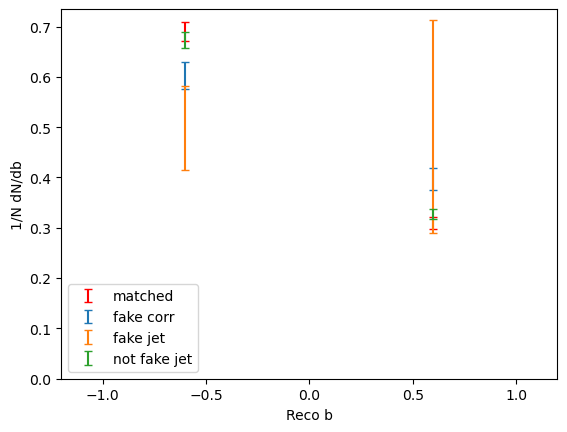

In [52]:
x=np.arange(range_low+(range_high-range_low)/(2*bins),range_high+(range_high-range_low)/(2*bins), (range_high-range_low)/bins)
#plt.errorbar(x, y_allreco_rec/sum(y_allreco_rec), yerr=yerr_allreco_rec/sum(y_allreco_rec), capsize=3, color='k', label='all reco', ls='none')
plt.errorbar(x, y_match_rec/sum(y_match_rec), yerr=yerr_match_rec/sum(y_match_rec), capsize=3, color='r', label='matched', ls='none')
#plt.errorbar(x, y_fake_rec/sum(y_fake_rec), yerr=yerr_fake_rec/sum(y_fake_rec), capsize=3, color='b', label='all fake', ls='none')
plt.errorbar(x, y_fakecorr_rec/sum(y_fakecorr_rec), yerr=yerr_fakecorr_rec/sum(y_fakecorr_rec), capsize=3, label='fake corr', ls='none')
plt.errorbar(x, y_fakejet_rec/sum(y_fakejet_rec), yerr=yerr_fakejet_rec/sum(y_fakejet_rec), capsize=3, label='fake jet', ls='none')
plt.errorbar(x, y_notfakejet_rec/sum(y_notfakejet_rec), yerr=yerr_notfakejet_rec/sum(y_notfakejet_rec), capsize=3, label='not fake jet', ls='none')
plt.legend()
plt.xlabel('Reco '+ob)
plt.ylabel('1/N dN/d'+ob)
plt.xlim(range_low,range_high)
plt.ylim(bottom=0)

In [53]:
print(y_fakejet_rec/sum(y_fakejet_rec))
print(yerr_fakejet_rec/sum(y_fakejet_rec))

[0.49836301 0.50163699]
[0.08264014 0.21178016]


In [54]:
print(y_fake_rec/sum(y_fake_rec))
print(yerr_fake_rec/sum(y_fake_rec))

[0.59417459 0.40582541]
[0.02493272 0.02715528]


In [55]:
(y_allreco_rec/sum(y_allreco_rec))/(y_match_rec/sum(y_match_rec))
print(y_fake_rec/sum(y_fake_rec))
print(y_fakejet_rec/sum(y_fakejet_rec))
print(y_fakecorr_rec/sum(y_fakecorr_rec))

[0.59417459 0.40582541]
[0.49836301 0.50163699]
[0.60287497 0.39712503]


In [56]:
df_match_30 = applyCut(df_match, '30 < pts < 40')
df_allreco_30 = applyCut(df_allreco, '30 < pts < 40')
df_fake_30 = applyCut(df_allfake, '30 < pts < 40')
df_fakejet_30 = applyCut(df_fakejet, '30 < pts < 40')
df_fakecorr_30 = applyCut(df_fakecorr, '30 < pts < 40')
df_notfakejet_30 = applyCut(df_notfakejet, '30 < pts < 40')

In [32]:
print(max(df_fakejet_30['w']))
print(max(df_notfakejet_30['w']))

3.416301019854018e-09
3.416301019854018e-09


In [57]:
y_match_rec,yerr_match_rec,x = calc_hist(df_match_30[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_match_30['w'])
y_allreco_rec,yerr_allreco_rec,x = calc_hist(df_allreco_30[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_allreco_30['w'])
y_fake_rec,yerr_fake_rec,x = calc_hist(df_fake_30[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_fake_30['w'])
y_fakejet_rec,yerr_fakejet_rec,x = calc_hist(df_fakejet_30[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_fakejet_30['w'])
y_fakecorr_rec,yerr_fakecorr_rec,x = calc_hist(df_fakecorr_30[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_fakecorr_30['w'])

(0.0, 1.159906207394859)

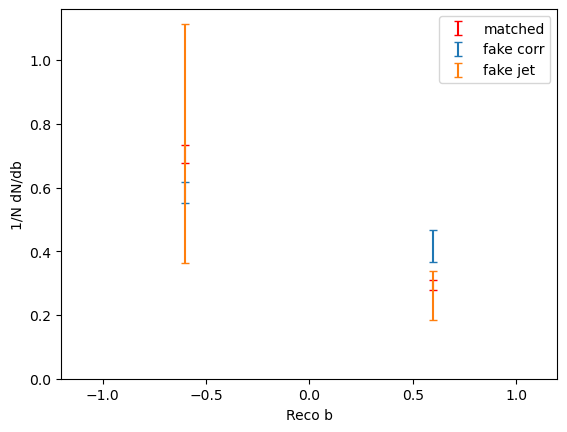

In [58]:
x=np.arange(range_low+(range_high-range_low)/(2*bins),range_high+(range_high-range_low)/(2*bins), (range_high-range_low)/bins)
#plt.errorbar(x, y_allreco_rec/sum(y_allreco_rec), yerr=yerr_allreco_rec/sum(y_allreco_rec), capsize=3, color='k', label='all reco', ls='none')
plt.errorbar(x, y_match_rec/sum(y_match_rec), yerr=yerr_match_rec/sum(y_match_rec), capsize=3, color='r', label='matched', ls='none')
#plt.errorbar(x, y_fake_rec/sum(y_fake_rec), yerr=yerr_fake_rec/sum(y_fake_rec), capsize=3, color='b', label='all fake', ls='none')
plt.errorbar(x, y_fakecorr_rec/sum(y_fakecorr_rec), yerr=yerr_fakecorr_rec/sum(y_fakecorr_rec), capsize=3, label='fake corr', ls='none')
plt.errorbar(x, y_fakejet_rec/sum(y_fakejet_rec), yerr=yerr_fakejet_rec/sum(y_fakejet_rec), capsize=3, label='fake jet', ls='none')
plt.legend()
plt.xlabel('Reco '+ob)
plt.ylabel('1/N dN/d'+ob)
plt.xlim(range_low,range_high)
plt.ylim(bottom=0)

In [59]:
print(y_fakejet_rec/sum(y_fakejet_rec))
print(yerr_fakejet_rec/sum(y_fakejet_rec))

[0.73790547 0.26209453]
[0.37559558 0.07669655]


In [60]:
print(y_fake_rec/sum(y_fake_rec))
print(yerr_fake_rec/sum(y_fake_rec))

[0.60064745 0.39935255]
[0.05058158 0.04618194]


In [139]:
(y_allreco_rec/sum(y_allreco_rec))/(y_match_rec/sum(y_match_rec))
y_fake_rec/sum(y_fake_rec)
print(y_fakejet_rec/sum(y_fakejet_rec))
print(y_fakecorr_rec/sum(y_fakecorr_rec))

[0.73790547 0.26209453]
[0.58383901 0.41616099]


pT correction

In [37]:
df_match_pts20 = applyCut(df_match, '20 < pts < 25')
df_match_pt20 = applyCut(df_match, '20 < pt < 25')
y_match_pts20,yerr_match_pts20,x = calc_hist(df_match_pts20[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_match_pts20['w'])
y_match_pt20,yerr_match_pt20,x = calc_hist(df_match_pt20[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_match_pt20['w'])

(0.0, 0.7474944555545767)

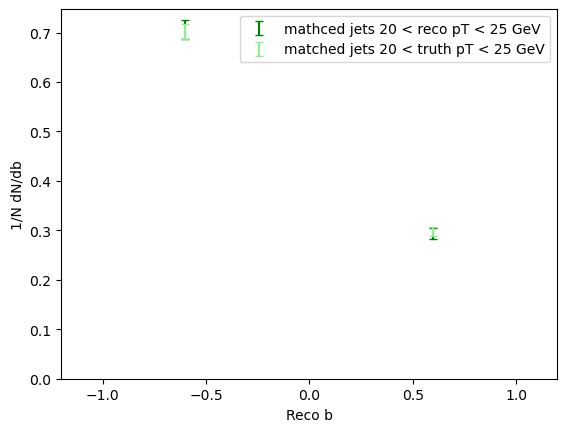

In [38]:
x=np.arange(range_low+(range_high-range_low)/(2*bins),range_high+(range_high-range_low)/(2*bins), (range_high-range_low)/bins)
plt.errorbar(x, y_match_pts20/sum(y_match_pts20), yerr=yerr_match_pts20/sum(y_match_pts20), capsize=3, color='g', label='mathced jets 20 < reco pT < 25 GeV', ls='none')
plt.errorbar(x, y_match_pt20/sum(y_match_pt20), yerr=yerr_match_pt20/sum(y_match_pt20), capsize=3, color='lightgreen', label='matched jets 20 < truth pT < 25 GeV', ls='none')
plt.legend()
plt.xlabel('Reco '+ob)
plt.ylabel('1/N dN/d'+ob)
plt.xlim(range_low,range_high)
plt.ylim(bottom=0)

In [42]:
print(y_match_pts20/sum(y_match_pts20), yerr_match_pts20/sum(y_match_pts20))
print(y_match_pt20/sum(y_match_pt20), yerr_match_pt20/sum(y_match_pt20))

[0.70636007 0.29363993] [0.0189809  0.01136867]
[0.70173958 0.29826042] [0.01564226 0.00932272]


In [39]:
(y_match_pt20/sum(y_match_pt20))/(y_match_pts20/sum(y_match_pts20))

array([0.99345873, 1.01573522])

In [79]:
df_match_pts25 = applyCut(df_match, '25 < pts < 30')
df_match_pt25 = applyCut(df_match, '25 < pt < 30')
y_match_pts25,yerr_match_pts25,x = calc_hist(df_match_pts25[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_match_pts25['w'])
y_match_pt25,yerr_match_pt25,x = calc_hist(df_match_pt25[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_match_pt25['w'])

In [80]:
print(y_match_pts25/sum(y_match_pts25), yerr_match_pts25/sum(y_match_pts25))
print(y_match_pt25/sum(y_match_pt25), yerr_match_pt25/sum(y_match_pt25))

[0.69049691 0.30950309] [0.01834966 0.0118916 ]
[0.68946964 0.31053036] [0.01453548 0.00902683]


(0.0, 0.7294083155665911)

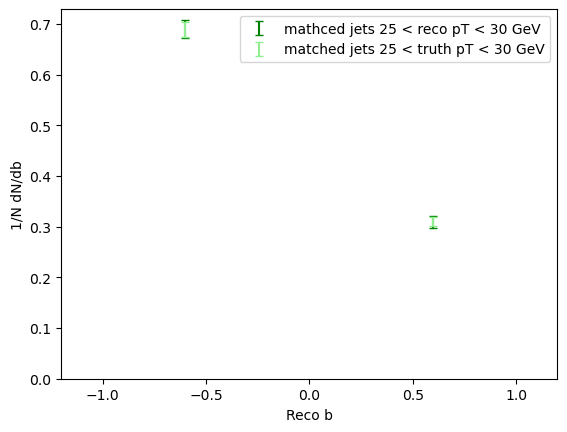

In [106]:
x=np.arange(range_low+(range_high-range_low)/(2*bins),range_high+(range_high-range_low)/(2*bins), (range_high-range_low)/bins)
plt.errorbar(x, y_match_pts25/sum(y_match_pts25), yerr=yerr_match_pts25/sum(y_match_pts25), capsize=3, color='g', label='mathced jets 25 < reco pT < 30 GeV', ls='none')
plt.errorbar(x, y_match_pt25/sum(y_match_pt25), yerr=yerr_match_pt25/sum(y_match_pt25), capsize=3, color='lightgreen', label='matched jets 25 < truth pT < 30 GeV', ls='none')
plt.legend()
plt.xlabel('Reco '+ob)
plt.ylabel('1/N dN/d'+ob)
plt.xlim(range_low,range_high)
plt.ylim(bottom=0)

In [107]:
(y_match_pt25/sum(y_match_pt25))/(y_match_pts25/sum(y_match_pts25))

array([0.99851228, 1.00331908])

In [82]:
df_match_pts30 = applyCut(df_match, '30 < pts < 40')
df_match_pt30 = applyCut(df_match, '30 < pt < 40')
y_match_pts30,yerr_match_pts30,x = calc_hist(df_match_pts30[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_match_pts30['w'])
y_match_pt30,yerr_match_pt30,x = calc_hist(df_match_pt30[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_match_pt30['w'])

In [83]:
print(y_match_pts30/sum(y_match_pts30), yerr_match_pts30/sum(y_match_pts30))
print(y_match_pt30/sum(y_match_pt30), yerr_match_pt30/sum(y_match_pt30))

[0.70483795 0.29516205] [0.02715301 0.01526591]
[0.68717103 0.31282897] [0.01796522 0.01489222]


(0.0, 0.7545957085052475)

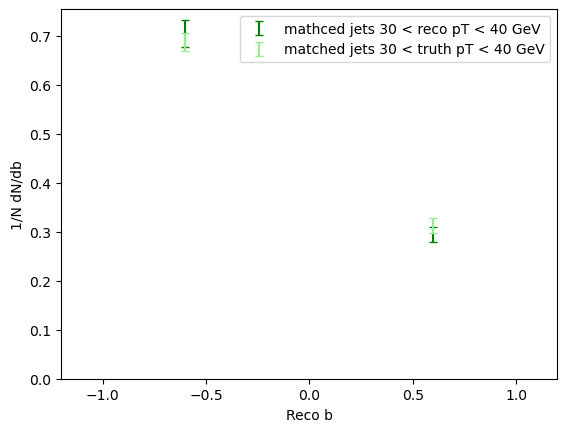

In [109]:
x=np.arange(range_low+(range_high-range_low)/(2*bins),range_high+(range_high-range_low)/(2*bins), (range_high-range_low)/bins)
plt.errorbar(x, y_match_pts30/sum(y_match_pts30), yerr=yerr_match_pts30/sum(y_match_pts30), capsize=3, color='g', label='mathced jets 30 < reco pT < 40 GeV', ls='none')
plt.errorbar(x, y_match_pt30/sum(y_match_pt30), yerr=yerr_match_pt30/sum(y_match_pt30), capsize=3, color='lightgreen', label='matched jets 30 < truth pT < 40 GeV', ls='none')
plt.legend()
plt.xlabel('Reco '+ob)
plt.ylabel('1/N dN/d'+ob)
plt.xlim(range_low,range_high)
plt.ylim(bottom=0)

In [110]:
(y_match_pt30/sum(y_match_pt30))/(y_match_pts30/sum(y_match_pts30))

array([0.97493477, 1.059855  ])

relax track matching

In [182]:
df = applyCut(df, 'distance1 < 0.05 and distance2 < 0.05')

In [183]:
rc_00 = getRc(applyCut(df,'15<pt<20'))
rc_err_00 = getRcErr(applyCut(df,'15<pt<20'))

In [184]:
rc_0 = getRc(applyCut(df,'20<pt<25'))
rc_err_0 = getRcErr(applyCut(df,'20<pt<25'))

In [185]:
rc_1 = getRc(applyCut(df,'25<pt<30'))
rc_err_1 = getRcErr(applyCut(df,'25<pt<30'))

In [186]:
rc_2 = getRc(applyCut(df,'30<pt<40'))
rc_err_2 = getRcErr(applyCut(df,'30<pt<40'))

In [187]:
rcs_00 = getRcs(applyCut(df,'15<pt<20'))
rcs_err_00 = getRcsErr(applyCut(df,'15<pt<20'))

In [188]:
rcs_0 = getRcs(applyCut(df,'20<pt<25'))
rcs_err_0 = getRcsErr(applyCut(df,'20<pt<25'))

In [189]:
rcs_1 = getRcs(applyCut(df,'25<pt<30'))
rcs_err_1 = getRcsErr(applyCut(df,'25<pt<30'))

In [190]:
rcs_2 = getRcs(applyCut(df,'30<pt<40'))
rcs_err_2 = getRcsErr(applyCut(df,'30<pt<40'))

Text(0.5, 1.0, 'Matching cut: truth pT > 15 GeV, truth Nch > 2, reco Nch > 2, dR(truth,reco) < 0.05')

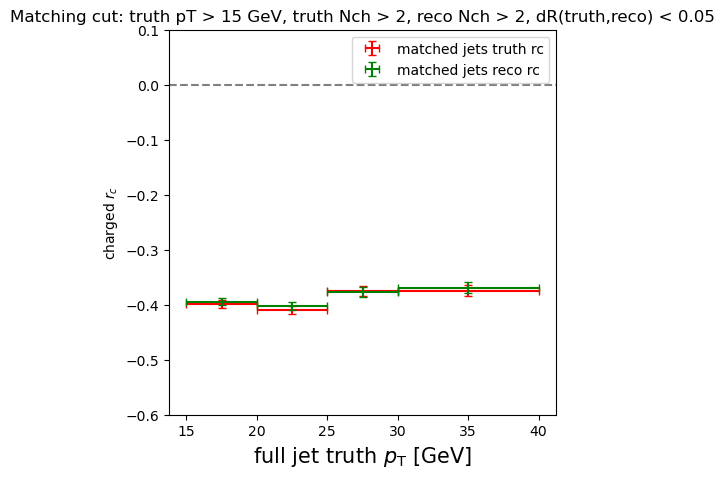

In [191]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([17.5, 22.5, 27.5, 35], [rc_00, rc_0, rc_1, rc_2], xerr=[2.5, 2.5, 2.5, 5], yerr=[rc_err_00, rc_err_0, rc_err_1, rc_err_2], capsize=3, color='r', ls='none', label='matched jets truth rc')
plt.errorbar([17.5, 22.5, 27.5, 35], [rcs_00, rcs_0, rcs_1, rcs_2], xerr=[2.5, 2.5, 2.5, 5], yerr=[rcs_err_00, rcs_err_0, rcs_err_1, rcs_err_2], capsize=3, color='g', ls='none', label='matched jets reco rc')
plt.xlabel('full jet truth $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('charged $r_c$')
plt.ylim(-0.6,0.1)
plt.legend()
plt.title('Matching cut: truth pT > 15 GeV, truth Nch > 2, reco Nch > 2, dR(truth,reco) < 0.05')

In [147]:
rc_00 = getRc(applyCut(df,'15<pts<20'))
rc_err_00 = getRcErr(applyCut(df,'15<pts<20'))

In [148]:
rc_0 = getRc(applyCut(df,'20<pts<25'))
rc_err_0 = getRcErr(applyCut(df,'20<pts<25'))

In [149]:
rc_1 = getRc(applyCut(df,'25<pts<30'))
rc_err_1 = getRcErr(applyCut(df,'25<pts<30'))

In [150]:
rc_2 = getRc(applyCut(df,'30<pts<40'))
rc_err_2 = getRcErr(applyCut(df,'30<pts<40'))

In [151]:
rcs_00 = getRcs(applyCut(df,'15<pts<20'))
rcs_err_00 = getRcsErr(applyCut(df,'15<pts<20'))

In [152]:
rcs_0 = getRcs(applyCut(df_match,'20<pts<25'))
rcs_err_0 = getRcsErr(applyCut(df_match,'20<pts<25'))

In [153]:
rcs_1 = getRcs(applyCut(df,'25<pts<30'))
rcs_err_1 = getRcsErr(applyCut(df,'25<pts<30'))

In [154]:
rcs_2 = getRcs(applyCut(df,'30<pts<40'))
rcs_err_2 = getRcsErr(applyCut(df,'30<pts<40'))

In [155]:
rcs_00_allreco = getRcs(applyCut(df_allreco,'15<pts<20'))
rcs_err_00_allreco = getRcsErr(applyCut(df_allreco,'15<pts<20'))

In [156]:
rcs_0_allreco = getRcs(applyCut(df_allreco,'20<pts<25'))
rcs_err_0_allreco = getRcsErr(applyCut(df_allreco,'20<pts<25'))

In [157]:
rcs_1_allreco = getRcs(applyCut(df_allreco,'25<pts<30'))
rcs_err_1_allreco = getRcsErr(applyCut(df_allreco,'25<pts<30'))

In [158]:
rcs_2_allreco = getRcs(applyCut(df_allreco,'30<pts<40'))
rcs_err_2_allreco = getRcsErr(applyCut(df_allreco,'30<pts<40'))

Text(0.5, 1.0, 'Matching cut: truth pT > 5 GeV, truth Nch > 2, reco Nch > 2, dR(truth,reco) < 0.05')

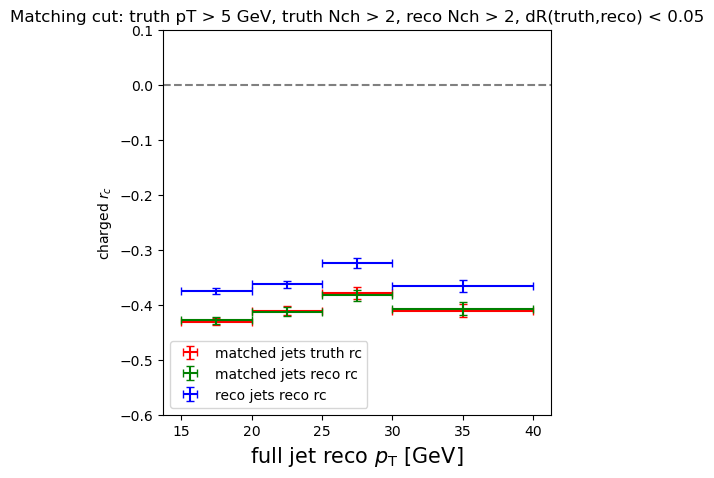

In [161]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([17.5, 22.5, 27.5, 35], [rc_00, rc_0, rc_1, rc_2], xerr=[2.5, 2.5, 2.5, 5], yerr=[rc_err_00, rc_err_0, rc_err_1, rc_err_2], capsize=3, color='r', ls='none', label='matched jets truth rc')
plt.errorbar([17.5, 22.5, 27.5, 35], [rcs_00, rcs_0, rcs_1, rcs_2], xerr=[2.5, 2.5, 2.5, 5], yerr=[rcs_err_00, rcs_err_0, rcs_err_1, rcs_err_2], capsize=3, color='g', ls='none', label='matched jets reco rc')
plt.errorbar([17.5, 22.5, 27.5, 35], [rcs_00_allreco, rcs_0_allreco, rcs_1_allreco, rcs_2_allreco], xerr=[2.5, 2.5, 2.5, 5], yerr=[rcs_err_00_allreco, rcs_err_0_allreco, rcs_err_1_allreco, rcs_err_2_allreco], capsize=3, color='b', ls='none', label='reco jets reco rc')
plt.xlabel('full jet reco $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('charged $r_c$')
plt.ylim(-0.6,0.1)
plt.legend()
plt.title('Matching cut: truth pT > 5 GeV, truth Nch > 2, reco Nch > 2, dR(truth,reco) < 0.05')